# How incremental SAGE works

`lm.importance.SAGE` shares out how much a model lowers the loss between its features, one instance
at a time. This notebook builds that idea up step by step:

1. what SAGE computes for one instance,
2. how values from many instances reach the right answer,
3. how its values add up, unlike those of PFI,
4. why the number of samples matters,
5. how the values follow a model as it learns and when the stream drifts,
6. how to use it with River classifiers, metrics and models with many outputs,
7. what it costs, and how it compares with batch SAGE.

It uses the same model and streams as [How incremental PFI works](01_how_pfi_works.ipynb), which
explains the storage and the tracker. The method is from
[Muschalik et al. (2023)](https://doi.org/10.1007/978-3-031-43418-1_26).

In [1]:
import itertools
import random

import matplotlib.pyplot as plt
import pandas as pd
from river import datasets, linear_model, metrics, multioutput, preprocessing

import limno as lm

# The feature colours are only used for features, the others for anything else
COLORS = {"a": "#2a78d6", "b": "#eb6834", "c": "#1baf7a"}
OTHERS = ["#6250d6", "#e87ba4", "#008300"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.bottom": False,
        "ytick.left": False,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def make_stream(n, drift_at=None, seed=0):
    """The target is `3a + b` (and `a + 3b` after the drift). `c` is never used."""
    rng = random.Random(seed)
    for i in range(n):
        x = {"a": rng.random(), "b": rng.random(), "c": rng.random()}
        if drift_at is not None and i >= drift_at:
            yield x, x["a"] + 3 * x["b"]
        else:
            yield x, 3 * x["a"] + x["b"]


def track(explainer, model, stream, every=100, learn=True):
    """Run the stream, and keep the importances every `every` instances."""
    steps, history = [], {}
    for i, (x, y) in enumerate(stream, start=1):
        explainer.learn_one(x, y)
        if learn:
            model.learn_one(x, y)
        if i % every == 0:
            steps.append(i)
            for feature, value in explainer.importances.items():
                history.setdefault(feature, []).append(value)
    return steps, history


def plot_importances(ax, steps, history, title):
    """One line per feature, named in the legend and at the end of the line."""
    for feature, values in history.items():
        ax.plot(steps, values, color=COLORS[feature], label=feature)
    ax.hlines(0, steps[0], steps[-1], color=MUTED, linewidth=0.8)
    # Labels are kept apart, for lines that end close together
    low, high = ax.get_ylim()
    y = low
    for feature in sorted(history, key=lambda f: history[f][-1]):
        y = max(history[feature][-1], y + 0.06 * (high - low))
        ax.annotate(
            feature,
            (steps[-1], y),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            color=INK,
        )
    ax.set_title(title)
    ax.set_xlabel("Instances")
    ax.set_ylabel("Importance")

## One instance by hand

SAGE starts with a model that knows no features, which can only predict the mean. It then reveals the
features one by one, and looks at how much each one lowers the loss. Features that are not revealed
yet take their values from a past instance:

$$\text{value of } f = \text{loss before revealing } f - \text{loss after revealing } f$$

Take a model that we know, `3a + b`, which ignores `c`. With values spread evenly between 0 and 1, its
mean prediction is 2. Each row below is one order in which to reveal the features.

In [2]:
class Known:
    def predict_one(self, x):
        return 3 * x["a"] + x["b"]


def reveal(model, x, past, y, y_mean, order):
    """What each feature adds when the features are revealed in this order."""
    previous_loss = abs(y - y_mean)
    values = {}
    for i, feature in enumerate(order, start=1):
        mixed = {f: x[f] if f in order[:i] else past[f] for f in x}
        loss = abs(y - model.predict_one(mixed))
        values[feature] = previous_loss - loss
        previous_loss = loss
    return values


model = Known()
past = {"a": 0.9, "b": 0.2, "c": 0.7}
x = {"a": 0.1, "b": 0.5, "c": 0.3}
y = model.predict_one(x)

orders = pd.DataFrame(
    {"".join(order): reveal(model, x, past, y, 2.0, order) for order in itertools.permutations(x)}
).T[["a", "b", "c"]]
orders["sum"] = orders.sum(axis=1)
orders.loc["mean"] = orders.mean()
orders.round(3)

,a,b,c,sum
abc,0.9,0.3,0.0,1.2
acb,0.9,0.3,0.0,1.2
bac,2.4,-1.2,0.0,1.2
bca,2.4,-1.2,0.0,1.2
cab,1.8,0.3,-0.9,1.2
cba,2.4,-0.3,-0.9,1.2
mean,1.8,-0.3,-0.3,1.2


The target is 0.8, so the mean prediction has a loss of 1.2, and the model is exact, so it has a loss
of 0. **Every row adds up to this drop of 1.2**, whatever the order.

The order does change how the drop is shared out. `a` gets 0.9 in `abc`, but 2.4 in `bac`. There, `b`
even gets -1.2, as revealing it while `a` still has its past value of 0.9 makes the prediction worse. No
single order is fair, so SAGE takes the mean over all orders, which is a Shapley value. That is the
last row.

The model ignores `c`, yet `c` gets -0.9 when it comes first. Revealing `c` changes nothing, but that
step replaces the mean prediction with one past instance, which is a worse guess here. We come back to
this in "How many samples?".

Going through all orders is far too slow with many features. So for each instance, `SAGE` picks one
random order, and the running mean does the rest.

## Many instances

With a squared loss and independent features, we can work out the true values: each feature gets the
variance it adds to the prediction. That is 3/4 for `a`, 1/12 for `b` and 0 for `c`. We use many samples
here, for reasons shown below.

`tracker.Mean` and `storage.UniformReservoir` weigh the whole stream the same, which suits this stream,
as nothing in it changes.

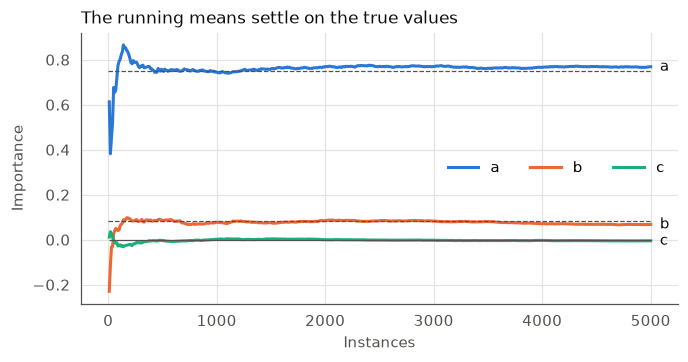

{'a': 0.769, 'b': 0.068, 'c': -0.005}

In [3]:
model = Known()
explainer = lm.importance.SAGE(
    model,
    metrics.MSE(),
    imputer=lm.imputer.Marginal(lm.storage.UniformReservoir(seed=1), seed=2),
    tracker=lm.tracker.Mean(),
    n_samples=50,
    seed=3,
)
steps, history = track(explainer, model, make_stream(5000), every=10, learn=False)

fig, ax = plt.subplots(figsize=(7, 3.2))
plot_importances(ax, steps, history, "The running means settle on the true values")
ax.hlines([3 / 4, 1 / 12], 0, steps[-1], color=MUTED, linewidth=0.8, linestyle="--")
ax.legend(loc="center right", ncols=3)
plt.show()

{feature: round(values[-1], 3) for feature, values in history.items()}

The dashed lines are the true values, and the running means end up close to them.

## The values add up

Now take a model where features only matter together, `4ab`. Replacing `a` hurts just as much as
replacing `b`, as both are needed. PFI replaces one feature at a time, so it counts all of this for
both. SAGE shares it. We can work out both: 8/9 per feature for PFI, and 7/18 for SAGE. The drop in loss
between predicting the mean and using the model is 7/9.

In [4]:
class Product:
    """The target is `4ab`, so `a` and `b` only matter together. `c` is never used."""

    def predict_one(self, x):
        return 4 * x["a"] * x["b"]


def make_product_stream(n, seed=0):
    rng = random.Random(seed)
    for _ in range(n):
        x = {"a": rng.random(), "b": rng.random(), "c": rng.random()}
        yield x, 4 * x["a"] * x["b"]


def uniform_pieces():
    return {
        "imputer": lm.imputer.Marginal(lm.storage.UniformReservoir(seed=1), seed=2),
        "tracker": lm.tracker.Mean(),
        "n_samples": 50,
    }


model = Product()
sage = lm.importance.SAGE(model, metrics.MSE(), seed=3, **uniform_pieces())
pfi = lm.importance.PFI(model, metrics.MSE(), **uniform_pieces())

y_mean, drop = lm.tracker.Mean(), lm.tracker.Mean()
for x, y in make_product_stream(5000):
    sage.learn_one(x, y)
    pfi.learn_one(x, y)
    y_mean.update(model.predict_one(x))
    drop.update((y - y_mean.get()) ** 2)

frame = pd.DataFrame({"PFI": pfi.importances, "SAGE": sage.importances})
frame.loc["sum"] = frame.sum()
frame.loc["drop in loss"] = drop.get()
frame.round(3)

,PFI,SAGE
a,0.894,0.391
b,0.860,0.390
c,0.000,-0.004
sum,1.754,0.777
drop in loss,0.777,0.777


Both are right about what they measure, and both rank `a` and `b` the same. But the PFI values add up to
more than twice the drop in loss, so they do not tell you what share of it each feature brings. The
SAGE values add up to the drop, so you can read `a` as bringing half of it. This holds as long as the
features of the stream do not change.

## How many samples?

At each step, `SAGE` averages predictions over `n_samples` past instances. This matters more than it
does for PFI.

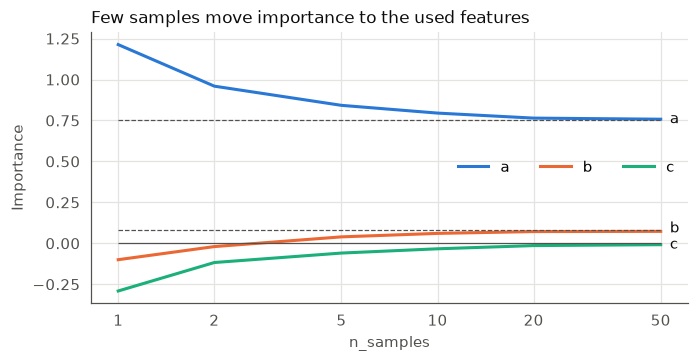

,a,b,c,sum
n_samples,,,,
1,1.213,-0.100,-0.291,0.822
2,0.959,-0.020,-0.117,0.822
5,0.842,0.039,-0.060,0.822
10,0.795,0.061,-0.034,0.822
20,0.764,0.072,-0.014,0.822
50,0.758,0.073,-0.009,0.822


In [5]:
def run_samples(n_samples, n=10_000):
    model = Known()
    explainer = lm.importance.SAGE(
        model,
        metrics.MSE(),
        imputer=lm.imputer.Marginal(lm.storage.UniformReservoir(seed=1), seed=2),
        tracker=lm.tracker.Mean(),
        n_samples=n_samples,
        seed=3,
    )
    for x, y in make_stream(n):
        explainer.learn_one(x, y)
    return explainer.importances


sweep = pd.DataFrame({m: run_samples(m) for m in (1, 2, 5, 10, 20, 50)}).T
sweep.index.name = "n_samples"

fig, ax = plt.subplots(figsize=(7, 3.2))
history = {feature: list(sweep[feature]) for feature in sweep}
plot_importances(ax, list(sweep.index), history, "Few samples move importance to the used features")
ax.hlines([3 / 4, 1 / 12], 1, 50, color=MUTED, linewidth=0.8, linestyle="--")
ax.set_xscale("log")
ax.set_xticks(list(sweep.index), list(sweep.index))
ax.set_xlabel("n_samples")
ax.legend(loc="center right", ncols=3)
plt.show()

sweep["sum"] = sweep.sum(axis=1)
sweep.round(3)

The dashed lines are the true values, and the sum is the same in every row. With one sample, `a` is
far too high, and `c`, which the model ignores, is well below zero.

A few past instances are a noisy stand-in for the hidden features, and that noise adds to the loss. So
the first step can make things worse, as with the -0.9 in the first section, and that falls on whichever
feature comes first. Revealing a feature that adds a lot of variance then removes a lot of
noise, for which it gets credit. More samples mean less noise, and the paper only proves that the values
reach the true ones as the number of samples grows.

**The sum stays right, so it does not warn you about this.** So a value far below zero may mean too few
samples, rather than a feature that hurts the model. The default is 5, which is a trade-off. Raise it
if the exact values matter.

## The values follow the model

So far the model was fixed. Here, a River model starts from nothing, with the same faster `alpha` as in
the PFI notebook, to see the start of the stream more clearly.

Call `explainer.learn_one` before `model.learn_one`, so that the instance is new to the model. The
explainer never updates the model: the loop does that.

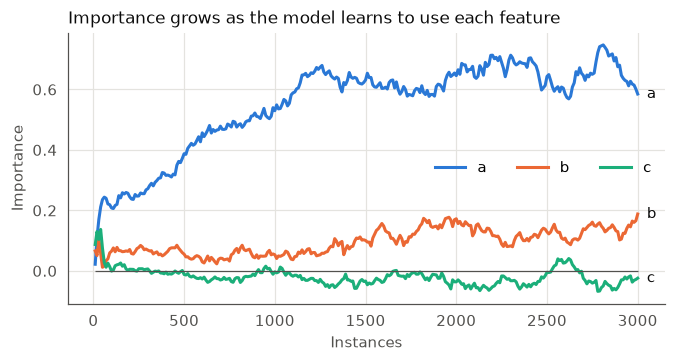

In [6]:
model = linear_model.LinearRegression()
explainer = lm.importance.SAGE(model, metrics.MAE(), tracker=lm.tracker.EWMean(alpha=0.01), seed=0)
steps, history = track(explainer, model, make_stream(3000), every=10)

fig, ax = plt.subplots(figsize=(7, 3.2))
plot_importances(ax, steps, history, "Importance grows as the model learns to use each feature")
ax.legend(loc="center right", ncols=3)
plt.show()

Each value grows as the model learns to use the feature. This uses an absolute loss, so the true values
are not the ones above. `c` stays just below zero, which fits the 5 samples.

## When the stream drifts

Halfway through this stream, the target moves from `3a + b` to `a + 3b`, so `a` and `b` swap roles. The
model is the same in both runs and adapts by itself. We only change how SAGE forgets, with the pieces
explained in the PFI notebook.

With a squared loss, the true values swap too. With 5 samples, the table in "How many samples?" tells us to
expect about 0.84 for the main feature, 0.04 for the other, and -0.06 for `c`.

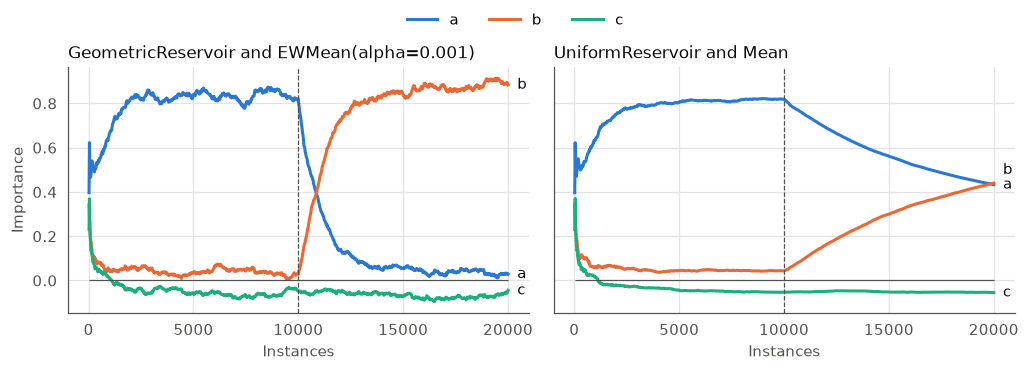

,GeometricReservoir and EWMean(alpha=0.001),UniformReservoir and Mean
a,0.029,0.433
b,0.884,0.440
c,-0.045,-0.054


In [7]:
DRIFT = 10_000


def run_drift(imputer, tracker):
    model = linear_model.LinearRegression()
    explainer = lm.importance.SAGE(model, metrics.MSE(), imputer=imputer, tracker=tracker, seed=3)
    return track(explainer, model, make_stream(2 * DRIFT, drift_at=DRIFT), every=20)


runs = {
    "GeometricReservoir and EWMean(alpha=0.001)": run_drift(
        lm.imputer.Marginal(lm.storage.GeometricReservoir(seed=1), seed=2),
        lm.tracker.EWMean(alpha=0.001),
    ),
    "UniformReservoir and Mean": run_drift(
        lm.imputer.Marginal(lm.storage.UniformReservoir(seed=1), seed=2),
        lm.tracker.Mean(),
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, (title, (steps, history)) in zip(axes, runs.items()):
    plot_importances(ax, steps, history, title)
    ax.axvline(DRIFT, color=MUTED, linewidth=0.8, linestyle="--")
    ax.set_xticks(range(0, 2 * DRIFT + 1, 5000))
axes[1].set_ylabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

pd.DataFrame({name: {f: v[-1] for f, v in run[1].items()} for name, run in runs.items()}).round(3)

The dashed line marks the drift. The left panel uses the default pieces. Its lines cross about 900
instances after the drift, and it ends close to the expected values. The right panel averages over the
whole stream, so by the end it sees `a` and `b` as about equal. That is a fair summary of the whole
stream, but not of the model at that point.

Use the pieces on the left unless you know that the stream does not change.

## River classifiers and metrics

Everything above works with any River model and any metric for numbers or probabilities, without any
adapter. `LogLoss` asks the model for probabilities, as in River's own evaluation.

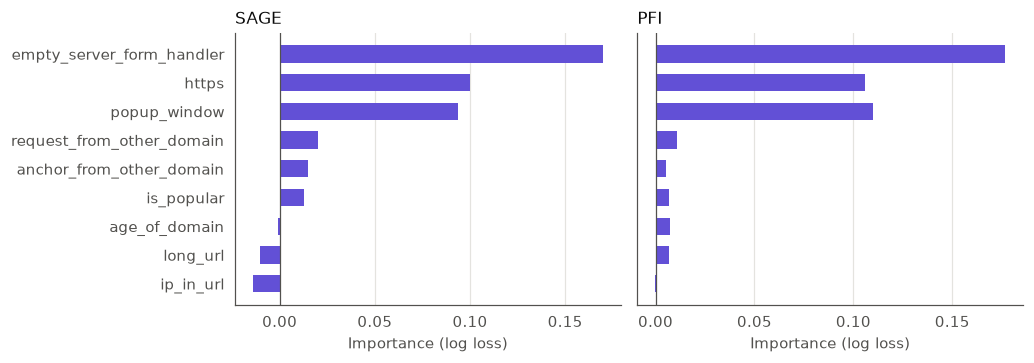

,SAGE,PFI
empty_server_form_handler,0.170,0.177
https,0.100,0.106
popup_window,0.094,0.110
request_from_other_domain,0.020,0.011
anchor_from_other_domain,0.015,0.005
is_popular,0.013,0.007
age_of_domain,-0.001,0.007
long_url,-0.010,0.007
ip_in_url,-0.014,-0.000


In [8]:
def phishing_importances(make_explainer):
    model = preprocessing.StandardScaler() | linear_model.LogisticRegression()
    explainer = make_explainer(model)
    for x, y in datasets.Phishing():
        explainer.learn_one(x, y)
        model.learn_one(x, y)
    return explainer.importances


frame = pd.DataFrame(
    {
        "SAGE": phishing_importances(lambda m: lm.importance.SAGE(m, metrics.LogLoss(), seed=42)),
        "PFI": phishing_importances(lambda m: lm.importance.PFI(m, metrics.LogLoss(), seed=42)),
    }
).sort_values("SAGE")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, name in zip(axes, frame):
    ax.barh(frame.index, frame[name], color=OTHERS[0], height=0.6)
    ax.locator_params(axis="x", nbins=5)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_title(name)
    ax.set_xlabel("Importance (log loss)")
fig.tight_layout()
plt.show()

frame.sort_values("SAGE", ascending=False).round(3)

Both find the same three main features, with `https` and `popup_window` close and swapped. Both use the
log loss here, so the numbers can be compared. The small values differ more, and SAGE has three just
below zero, which fits what we saw with few samples.

`SAGE` averages predictions before it computes the loss, and labels cannot be averaged. So unlike
`PFI`, it does not take a metric for labels, and gives an error right away:

In [9]:
model = preprocessing.StandardScaler() | linear_model.LogisticRegression()
try:
    lm.importance.SAGE(model, metrics.Accuracy())
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: Accuracy needs labels, but SAGE averages predictions. Use a metric for probabilities, such as LogLoss


Use `MAE`, `MSE`, `LogLoss` or `CrossEntropy`. As with PFI, the loss is computed on one instance at a
time, so `ROCAUC` runs but does not give useful values.

## Models with many outputs

`lm.multioutput.PerOutput` gives the values of each output. Here, `y1` is `3a + b` and `y2` is `a + 3b`.

In [10]:
def make_two_outputs(n, seed=0):
    """`y1` is `3a + b` and `y2` is `a + 3b`. `c` is never used."""
    for x, y1 in make_stream(n, seed=seed):
        yield x, {"y1": y1, "y2": x["a"] + 3 * x["b"]}


model = multioutput.RegressorChain(linear_model.LinearRegression(), order=["y1", "y2"])
per_output = lm.multioutput.PerOutput(
    model, lambda output: lm.importance.SAGE(output, metrics.MSE(), seed=42)
)
for x, y in make_two_outputs(10_000):
    per_output.learn_one(x, y)
    model.learn_one(x, y)

pd.DataFrame(per_output.importances).round(3)

,y1,y2
a,0.817,0.057
b,0.045,0.822
c,-0.062,-0.063


Each output finds its own main feature, with values close to what 5 samples gave above. For the details
of `PerOutput`, including how it behaves with chains, see the PFI notebook.

## What it costs

Each instance takes one prediction as it is, and then `n_samples` predictions for each step. The last
step reveals the last feature, so nothing is hidden and it can reuse the first prediction.

In [11]:
class Counting(Known):
    calls = 0

    def predict_one(self, x):
        self.calls += 1
        return super().predict_one(x)


rows = []
for n_samples in (1, 5, 20):
    estimates = []
    for seed in range(20):
        model = Counting()
        explainer = lm.importance.SAGE(
            model, metrics.MSE(), tracker=lm.tracker.Mean(), n_samples=n_samples, seed=seed
        )
        for x, y in make_stream(500, seed=seed):
            explainer.learn_one(x, y)
        estimates.append(explainer.importances["a"])
    rows.append(
        {
            "n_samples": n_samples,
            "predictions per instance": model.calls / 499,
            "mean of a": sum(estimates) / len(estimates),
            "spread of a (std)": pd.Series(estimates).std(),
        }
    )
pd.DataFrame(rows).set_index("n_samples").round(3)

,predictions per instance,mean of a,spread of a (std)
n_samples,,,
1,3.0,1.238,0.100
5,11.0,0.860,0.038
20,41.0,0.779,0.034


This is 3 features over 500 instances and 20 seeds, where the true value of `a` is 3/4. The predictions
are `1 + (n_features - 1) * n_samples`, so a little less than PFI for the same `n_samples`.

The main difference is in what samples buy. In the PFI notebook, the mean stays near the true value for
all `n_samples`, and more samples only lower the spread. Here, the mean itself moves towards the true
value, so `n_samples=1` is not a good choice even when the spread is fine for you.

## Does it match batch SAGE?

As a last check, we freeze a trained model and compare with batch SAGE on a fixed dataset, written here
without using limno. It computes the mean prediction once, and takes past values from the whole
dataset. If nothing changes, the two should agree. Both use the same number of samples and three passes
over the data.

In [12]:
stream = list(datasets.synth.Friedman(seed=7).take(12_000))
model = preprocessing.StandardScaler() | linear_model.LinearRegression()
for x, y in stream[:8000]:
    model.learn_one(x, y)
test = stream[8000:]
y_mean = sum(model.predict_one(x) for x, _ in test) / len(test)

N_SAMPLES, N_RUNS = 5, 3
rng = random.Random(0)
batch = {feature: 0.0 for feature in test[0][0]}
for _ in range(N_RUNS):
    for x, y in test:
        order = list(x)
        rng.shuffle(order)
        previous_loss = abs(y - y_mean)
        for i, feature in enumerate(order, start=1):
            predictions = []
            for _ in range(N_SAMPLES):
                past = rng.choice(test)[0]
                predictions.append(model.predict_one({**x, **{f: past[f] for f in order[i:]}}))
            loss = abs(y - sum(predictions) / N_SAMPLES)
            batch[feature] += (previous_loss - loss) / (N_RUNS * len(test))
            previous_loss = loss

explainer = lm.importance.SAGE(
    model,
    metrics.MAE(),
    imputer=lm.imputer.Marginal(lm.storage.UniformReservoir(size=500, seed=1), seed=2),
    tracker=lm.tracker.Mean(),
    n_samples=N_SAMPLES,
    seed=3,
)
for _ in range(N_RUNS):
    for x, y in test:
        explainer.learn_one(x, y)

pd.DataFrame({"batch": batch, "incremental": explainer.importances}).round(3)

,batch,incremental
0,0.422,0.430
1,0.396,0.388
2,-0.026,-0.036
3,0.902,0.920
4,0.197,0.221
5,-0.033,-0.047
6,-0.044,-0.039
7,-0.024,-0.008
8,-0.003,-0.016
9,-0.010,-0.036


The two agree closely, with a largest difference of about 0.03. Features 5 to 9 are not used to build the
target, and they are close to zero or just below it in both. Unlike batch SAGE, the incremental version
needs no second pass over the data, and gives values while the stream is running.

## Summary

| Question | Answer |
|---|---|
| What does a value mean? | How much the loss drops when the feature is revealed, averaged over random orders. |
| What do the values add up to? | The drop in loss between predicting the mean and using the model. |
| When do I call it? | `explainer.learn_one(x, y)` before `model.learn_one(x, y)`. |
| Where do I read it? | `explainer.importances`, at any time. |
| What does it cost? | `1 + (n_features - 1) * n_samples` predictions per instance. |
| How many samples? | 5 by default. Few samples push unused features below zero, and the sum does not show it. |
| Which metrics? | Metrics for numbers or probabilities, not for labels. |
| Stream that changes | The default pieces: `GeometricReservoir` and `EWMean`. |
| Stream that does not change | `UniformReservoir` and `Mean`. |
| Correlated features | It replaces features independently, so it can make unrealistic instances. |

The [API reference](../docs/api/index.md) has the details.